
# Notebook 1 — Cadrage et analyse exploratoire des données

## Objectif

Ce notebook présente une première analyse du jeu de données UNSW-NB15 dans le cadre d'un projet de détection de comportements atypiques dans le trafic réseau.

L'objectif est d'examiner la structure des données, la répartition des observations, les distributions des variables et les éventuels problèmes de qualité avant la modélisation.

Les fichiers d'entraînement et de test sont conservés séparément. Les étiquettes d'attaque sont utilisées ici uniquement pour l'analyse exploratoire et l'audit des données.

---


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
plt.rcParams["figure.figsize"] = (8, 4)



## 1. Chargement et structure du jeu de données

Deux fichiers CSV sont chargés : un jeu d'entraînement de 82 332 observations et un jeu de test de 175 341 observations.

Chaque fichier contient 45 colonnes, comprenant des caractéristiques du trafic réseau, un identifiant (`id`) et deux variables d'étiquetage (`label` et `attack_cat`).

L'analyse vérifie également la correspondance des colonnes et de leurs types entre les deux fichiers, ainsi que la présence éventuelle de valeurs manquantes.

---


In [4]:
# Chargement des fichiers CSV
df_train = pd.read_csv("UNSW_NB15_training-set.csv")
df_test = pd.read_csv("UNSW_NB15_testing-set.csv")

# Affichage des dimensions
print("Dimensions du Training :", df_train.shape)
print("Dimensions du Testing :", df_test.shape)


Dimensions du Training : (82332, 45)
Dimensions du Testing : (175341, 45)


In [5]:
# Afficher les 5 premières lignes du dataset
df_train.head()


,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sttl,dttl,sload,dload,sloss,dloss,sinpkt,dinpkt,sjit,djit,swin,stcpb,dtcpb,dwin,tcprtt,synack,ackdat,smean,dmean,trans_depth,response_body_len,ct_srv_src,ct_state_ttl,ct_dst_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.000011,udp,-,INT,2,0,496,0,90909.0902,254,0,180363632.0,0.0,0,0,0.011,0.0,0.0,0.0,0,0,0,0,0.0,0.0,0.0,248,0,0,0,2,2,1,1,1,2,0,0,0,1,2,0,Normal,0
1,2,0.000008,udp,-,INT,2,0,1762,0,125000.0003,254,0,881000000.0,0.0,0,0,0.008,0.0,0.0,0.0,0,0,0,0,0.0,0.0,0.0,881,0,0,0,2,2,1,1,1,2,0,0,0,1,2,0,Normal,0
2,3,0.000005,udp,-,INT,2,0,1068,0,200000.0051,254,0,854400000.0,0.0,0,0,0.005,0.0,0.0,0.0,0,0,0,0,0.0,0.0,0.0,534,0,0,0,3,2,1,1,1,3,0,0,0,1,3,0,Normal,0
3,4,0.000006,udp,-,INT,2,0,900,0,166666.6608,254,0,600000000.0,0.0,0,0,0.006,0.0,0.0,0.0,0,0,0,0,0.0,0.0,0.0,450,0,0,0,3,2,2,2,1,3,0,0,0,2,3,0,Normal,0
4,5,0.000010,udp,-,INT,2,0,2126,0,100000.0025,254,0,850400000.0,0.0,0,0,0.010,0.0,0.0,0.0,0,0,0,0,0.0,0.0,0.0,1063,0,0,0,3,2,2,2,1,3,0,0,0,2,3,0,Normal,0


In [6]:
# Afficher les informations générales du dataset
df_train.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 82332 entries, 0 to 82331
Data columns (total 45 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 82332 non-null  int64  
 1   dur                82332 non-null  float64
 2   proto              82332 non-null  object 
 3   service            82332 non-null  object 
 4   state              82332 non-null  object 
 5   spkts              82332 non-null  int64  
 6   dpkts              82332 non-null  int64  
 7   sbytes             82332 non-null  int64  
 8   dbytes             82332 non-null  int64  
 9   rate               82332 non-null  float64
 10  sttl               82332 non-null  int64  
 11  dttl               82332 non-null  int64  
 12  sload              82332 non-null  float64
 13  dload              82332 non-null  float64
 14  sloss              82332 non-null  int64  
 15  dloss              82332 non-null  int64  
 16  sinpkt             823

In [7]:
# Comparaison de la structure des deux fichiers
print("Colonnes identiques :", df_train.columns.equals(df_test.columns))

print("Types identiques :", df_train.dtypes.equals(df_test.dtypes))

print("Valeurs manquantes dans Training :", df_train.isna().sum().sum())

print("Valeurs manquantes dans Testing :", df_test.isna().sum().sum())


Colonnes identiques : True
Types identiques : True
Valeurs manquantes dans Training : 0
Valeurs manquantes dans Testing : 0



## 2. Analyse des variables catégorielles et des étiquettes

Les variables catégorielles étudiées sont `proto`, `service` et `state`. Elles décrivent respectivement le protocole réseau, le service et l'état de la communication.

Dans le jeu d'entraînement, `proto` possède 131 catégories, `service` en possède 13 et `state` en possède 7. Certaines catégories sont nettement plus représentées que d'autres.

La variable `label` distingue 37 000 observations normales et 45 332 observations associées à des attaques. La variable `attack_cat` permet de consulter les catégories d'attaques présentes dans le jeu de données.

Ces étiquettes servent à décrire et à évaluer les observations, mais ne constituent pas des variables explicatives utilisées pour calculer les distances ou construire les clusters.

---


In [8]:
# Analyse des variables catégorielles
colonnes_categorielles = ["proto", "service", "state"]

for colonne in colonnes_categorielles:
    print(f"\n--- {colonne} ---")
    print("Nombre de catégories :", df_train[colonne].nunique())
    print(df_train[colonne].value_counts().head(10))



--- proto ---
Nombre de catégories : 131
proto
tcp     43095
udp     29418
unas     3515
arp       987
ospf      676
sctp      324
any        96
gre        88
rsvp       64
ipv6       61
Name: count, dtype: int64

--- service ---
Nombre de catégories : 13
service
-           47153
dns         21367
http         8287
smtp         1851
ftp          1552
ftp-data     1396
pop3          423
ssh           204
ssl            30
snmp           29
Name: count, dtype: int64

--- state ---
Nombre de catégories : 7
state
FIN    39339
INT    34163
CON     6982
REQ     1842
ACC        4
RST        1
CLO        1
Name: count, dtype: int64


In [9]:
# Répartition du trafic normal et des attaques
print("--- Répartition de label ---")
print(df_train["label"].value_counts())

print("\n--- Répartition de attack_cat ---")
print(df_train["attack_cat"].value_counts())


--- Répartition de label ---
label
1    45332
0    37000
Name: count, dtype: int64

--- Répartition de attack_cat ---
attack_cat
Normal            37000
Generic           18871
Exploits          11132
Fuzzers            6062
DoS                4089
Reconnaissance     3496
Analysis            677
Backdoor            583
Shellcode           378
Worms                44
Name: count, dtype: int64



## 3. Statistiques descriptives et distributions numériques

Les statistiques descriptives permettent d'examiner les valeurs minimales, maximales, moyennes et médianes des variables numériques.

Les histogrammes de `dur`, `spkts`, `sbytes` et `rate` mettent en évidence des distributions asymétriques, avec des concentrations importantes de valeurs et des observations beaucoup plus élevées.

Une transformation logarithmique `log(1 + x)` est ensuite appliquée à ces quatre variables à des fins de visualisation. Elle améliore la lisibilité des distributions, sans remplacer les données originales ni constituer ici une transformation du pipeline de modélisation.

Ces résultats soulignent l'importance d'un prétraitement adapté avant l'utilisation de méthodes reposant sur des distances.

---


In [10]:
# Statistiques descriptives des variables numériques
df_train.describe().T


,count,mean,std,min,25%,50%,75%,max
id,82332.0,4.116650e+04,2.376735e+04,1.0,20583.750000,4.116650e+04,6.174925e+04,8.233200e+04
dur,82332.0,1.006756e+00,4.710444e+00,0.0,0.000008,1.413800e-02,7.193603e-01,5.999999e+01
spkts,82332.0,1.866647e+01,1.339164e+02,1.0,2.000000,6.000000e+00,1.200000e+01,1.064600e+04
dpkts,82332.0,1.754594e+01,1.155741e+02,0.0,0.000000,2.000000e+00,1.000000e+01,1.101800e+04
sbytes,82332.0,7.993908e+03,1.716423e+05,24.0,114.000000,5.340000e+02,1.280000e+03,1.435577e+07
dbytes,82332.0,1.323379e+04,1.514715e+05,0.0,0.000000,1.780000e+02,9.560000e+02,1.465753e+07
rate,82332.0,8.241089e+04,1.486204e+05,0.0,28.606114,2.650177e+03,1.111111e+05,1.000000e+06
sttl,82332.0,1.809677e+02,1.015134e+02,0.0,62.000000,2.540000e+02,2.540000e+02,2.550000e+02
dttl,82332.0,9.571300e+01,1.166677e+02,0.0,0.000000,2.900000e+01,2.520000e+02,2.530000e+02
sload,82332.0,6.454902e+07,1.798618e+08,0.0,11202.466797,5.770032e+05,6.514286e+07,5.268000e+09


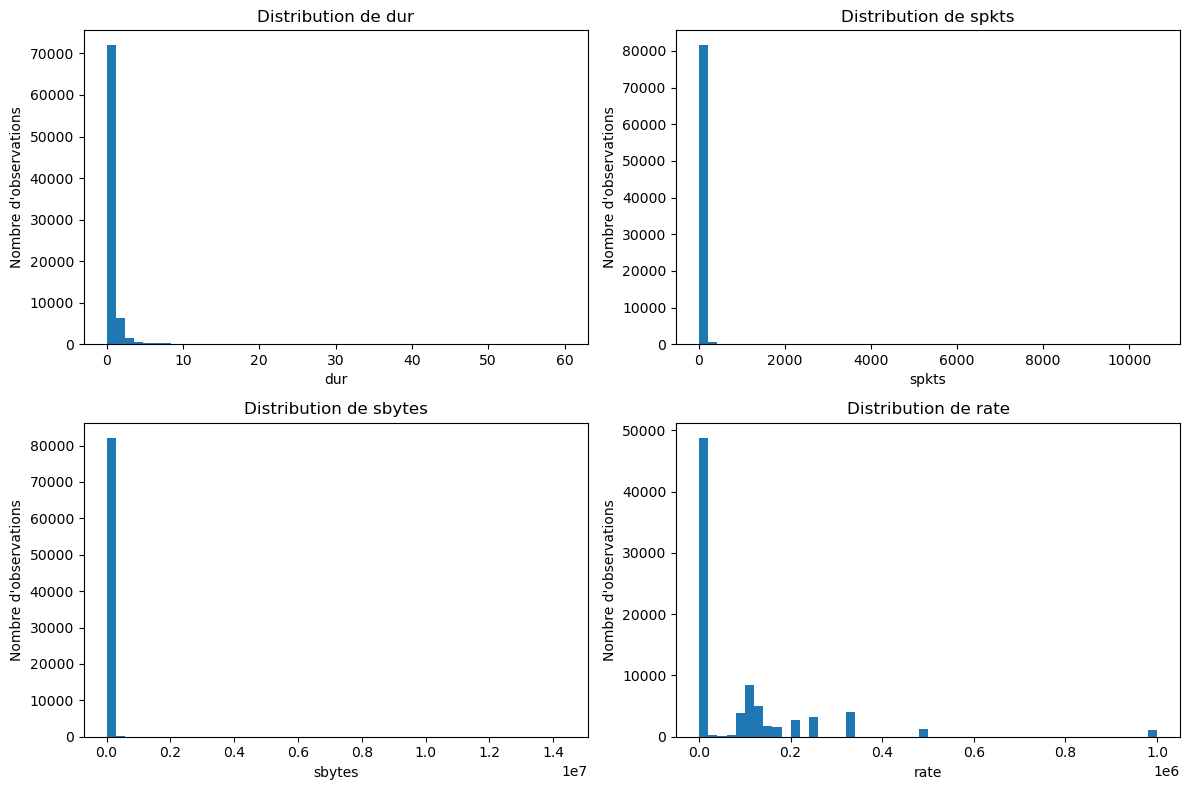

In [11]:
# Visualisation des distributions numériques
variables = ["dur", "spkts", "sbytes", "rate"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, variable in zip(axes.flatten(), variables):
    ax.hist(df_train[variable], bins=50)
    ax.set_title(f"Distribution de {variable}")
    ax.set_xlabel(variable)
    ax.set_ylabel("Nombre d'observations")

plt.tight_layout()
plt.show()


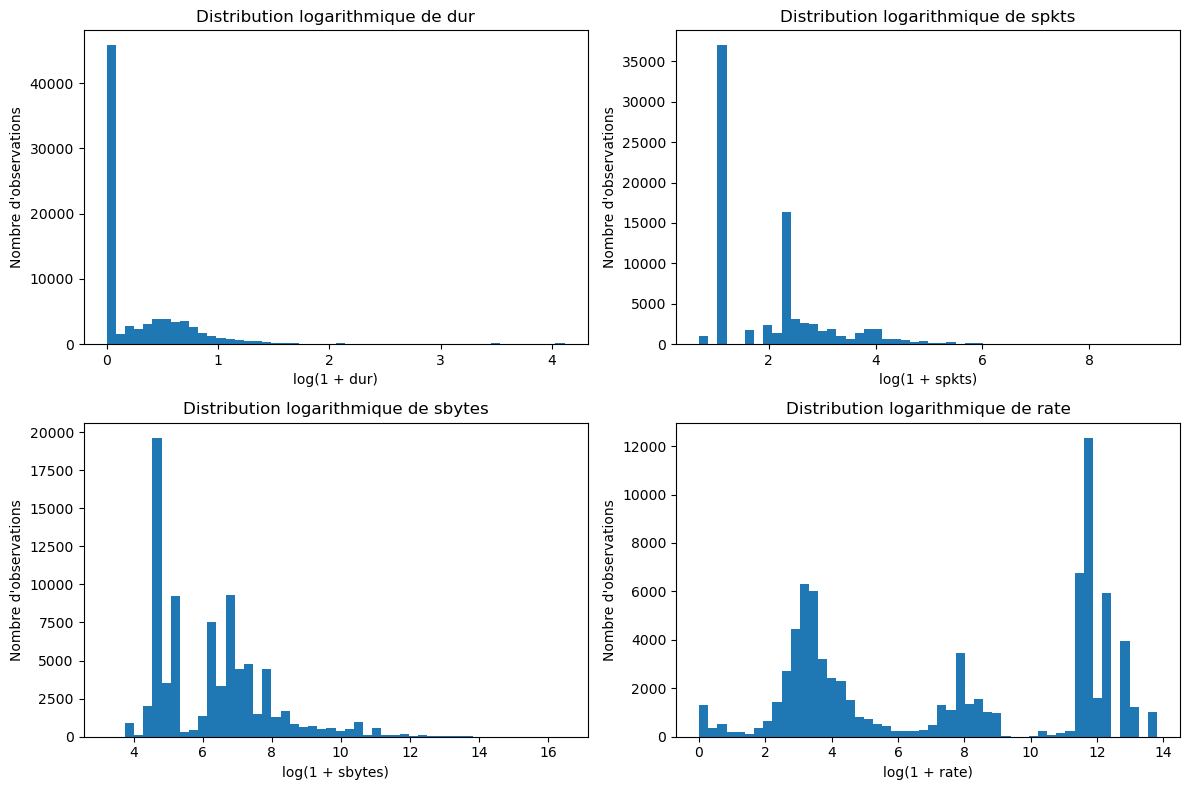

In [12]:
# Visualisation des distributions après transformation logarithmique
variables = ["dur", "spkts", "sbytes", "rate"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, variable in zip(axes.flatten(), variables):
    valeurs_log = np.log1p(df_train[variable])

    ax.hist(valeurs_log, bins=50)
    ax.set_title(f"Distribution logarithmique de {variable}")
    ax.set_xlabel(f"log(1 + {variable})")
    ax.set_ylabel("Nombre d'observations")

plt.tight_layout()
plt.show()



## 4. Analyse des doublons et des profils communs

Aucun doublon exact n'est détecté lorsque toutes les colonnes sont prises en compte.

En excluant l'identifiant `id`, 26 387 doublons sont recensés dans le jeu d'entraînement et 67 601 dans le jeu de test.

Après exclusion de `id`, `label` et `attack_cat`, l'analyse identifie également 1 302 profils de caractéristiques présents dans les deux fichiers.

Ces observations identiques ne sont pas automatiquement considérées comme des erreurs : plusieurs communications peuvent partager les mêmes caractéristiques. Aucune suppression systématique n'est effectuée à cette étape.

---


In [13]:
# Vérification des doublons

# Doublons exacts, avec toutes les colonnes
print("Doublons exacts (Training) :", df_train.duplicated().sum())
print("Doublons exacts (Testing) :", df_test.duplicated().sum())

# Doublons en excluant l'identifiant
colonnes_sans_id = df_train.columns.drop("id")

print("Doublons sans ID (Training) :",
      df_train.duplicated(subset=colonnes_sans_id).sum())

print("Doublons sans ID (Testing) :",
      df_test.duplicated(subset=colonnes_sans_id).sum())


Doublons exacts (Training) : 0
Doublons exacts (Testing) : 0
Doublons sans ID (Training) : 26387
Doublons sans ID (Testing) : 67601


In [14]:
# Vérification des observations communes entre Training et Testing

# Exclure l'identifiant et les étiquettes
colonnes_features = df_train.columns.drop(
    ["id", "label", "attack_cat"]
)

# Conserver les profils uniques de chaque fichier
train_unique = df_train[colonnes_features].drop_duplicates()
test_unique = df_test[colonnes_features].drop_duplicates()

# Identifier les profils présents dans les deux fichiers
profils_communs = train_unique.merge(
    test_unique,
    on=list(colonnes_features),
    how="inner"
)

print("Profils uniques dans Training :", len(train_unique))
print("Profils uniques dans Testing :", len(test_unique))
print("Profils communs aux deux fichiers :", len(profils_communs))


Profils uniques dans Training : 53946
Profils uniques dans Testing : 101040
Profils communs aux deux fichiers : 1302



## 5. Vérification de la cohérence des étiquettes

Un audit est réalisé sur les deux fichiers réunis afin d'identifier les profils de trafic possédant les mêmes caractéristiques explicatives, mais associés à des valeurs différentes de `label`.

L'analyse révèle 414 profils contradictoires, représentant 1 758 observations, soit environ 0,68 % de l'ensemble des données.

Cette situation constitue une limite pour l'évaluation : des observations identiques du point de vue des caractéristiques disponibles peuvent être associées à des étiquettes différentes.

La réunion des deux fichiers est utilisée uniquement pour cet audit. Elle ne constitue pas un regroupement des données pour entraîner les modèles.

---


In [15]:
# Vérification de la cohérence des étiquettes

# Réunir les deux fichiers pour l'audit uniquement
df_audit = pd.concat(
    [df_train, df_test],
    ignore_index=True
)

# Nombre d'étiquettes différentes par profil réseau
nb_labels = df_audit.groupby(
    list(colonnes_features),
    dropna=False
)["label"].nunique()

# Profils associés à plusieurs étiquettes
profils_contradictoires = (nb_labels > 1).sum()

print("Profils avec des étiquettes contradictoires :",
      profils_contradictoires)


Profils avec des étiquettes contradictoires : 414


In [16]:
# Quantifier les observations associées aux profils contradictoires

# Récupérer les profils contradictoires
cles_contradictoires = nb_labels[
    nb_labels > 1
].reset_index()[list(colonnes_features)]

# Retrouver toutes les observations correspondantes
observations_contradictoires = df_audit.merge(
    cles_contradictoires,
    on=list(colonnes_features),
    how="inner"
)

print("Nombre de profils contradictoires :",
      len(cles_contradictoires))

print("Nombre d'observations concernées :",
      len(observations_contradictoires))

print("Pourcentage du dataset concerné :",
      round(len(observations_contradictoires) / len(df_audit) * 100, 2), "%")


Nombre de profils contradictoires : 414
Nombre d'observations concernées : 1758
Pourcentage du dataset concerné : 0.68 %



## 6. Analyse des variables constantes et presque constantes

Aucune variable strictement constante n'est identifiée dans le jeu d'entraînement.

Deux variables sont presque constantes selon le seuil de fréquence de 99 % : `is_ftp_login` (99,18 %) et `ct_ftp_cmd` (99,17 %). Leur valeur dominante est 0.

Ces variables présentent une faible variabilité globale, mais peuvent conserver une information utile pour certaines communications. Elles ne sont donc pas supprimées automatiquement à ce stade.

---


In [17]:
# Vérification des variables constantes

# Nombre de valeurs différentes par colonne
nb_valeurs_uniques = df_train.nunique()

# Identifier les colonnes avec une seule valeur
variables_constantes = nb_valeurs_uniques[
    nb_valeurs_uniques == 1
]

print("Nombre de variables constantes :",
      len(variables_constantes))

print("\nVariables constantes :")
print(variables_constantes)


Nombre de variables constantes : 0

Variables constantes :
Series([], dtype: int64)


In [18]:
# Vérification des variables presque constantes

frequences_max = df_train.apply(
    lambda colonne: colonne.value_counts(normalize=True).iloc[0]
)

variables_presque_constantes = frequences_max[
    frequences_max >= 0.99
].sort_values(ascending=False)

print("Nombre de variables presque constantes :",
      len(variables_presque_constantes))

print("\nVariables presque constantes :")
print((variables_presque_constantes * 100).round(2))


Nombre de variables presque constantes : 2

Variables presque constantes :
is_ftp_login    99.18
ct_ftp_cmd      99.17
dtype: float64


In [19]:
# Analyse détaillée des variables presque constantes

for colonne in variables_presque_constantes.index:
    print(f"\n--- {colonne} ---")
    print(df_train[colonne].value_counts().sort_index())



--- is_ftp_login ---
is_ftp_login
0    81654
1      674
2        4
Name: count, dtype: int64

--- ct_ftp_cmd ---
ct_ftp_cmd
0    81652
1      670
2       10
Name: count, dtype: int64



## 7. Vérification des valeurs infinies

La recherche de valeurs infinies dans les colonnes numériques ne révèle aucune valeur `inf` ou `-inf`, ni dans le jeu d'entraînement ni dans le jeu de test.

---


In [20]:
# Vérification des valeurs infinies

# Sélectionner uniquement les colonnes numériques
colonnes_numeriques = df_train.select_dtypes(
    include=[np.number]
).columns

# Compter les valeurs infinies dans chaque fichier
inf_train = np.isinf(df_train[colonnes_numeriques]).sum().sum()
inf_test = np.isinf(df_test[colonnes_numeriques]).sum().sum()

print("Valeurs infinies dans Training :", inf_train)
print("Valeurs infinies dans Testing :", inf_test)


Valeurs infinies dans Training : 0
Valeurs infinies dans Testing : 0



## Bilan de l'analyse exploratoire

Les deux fichiers présentent une structure compatible, sans valeurs manquantes ni infinies détectées.

L'analyse a néanmoins mis en évidence des distributions numériques asymétriques, des observations répétées, des variables presque constantes et certains profils associés à des étiquettes contradictoires.

Ces constats orientent la suite du projet vers un prétraitement des variables numériques et catégorielles, suivi de l'application de méthodes de détection de comportements atypiques. Les paramètres de préparation devront être appris sur les données d'entraînement afin de préserver l'indépendance du jeu de test.
